CMP6221 Computing for AI
Assessment 1 AI Based Computing Program
Case Study: Telco Customer Churn Prediction and Behavioral Segmentation

Student Name: Abdullah Aijaz

Academic Year: 2026 to 2027

This notebook demonstrates an end to end Machine Learning pipeline utilizing Python, scikit learn Pipelines, and Object Oriented Programming. The system implements strict data leakage prevention, missing value imputation on training folds, unsupervised clustering (K Means and PCA), and supervised classification (Logistic Regression and Random Forest with GridSearchCV).

Part 1: Execute End to End Leakage Free Pipeline
The CustomerChurnPipeline class serves as the single source of truth for all data processing, modeling, and evaluation.

In [1]:
from customer_churn_pipeline import CustomerChurnPipeline

pipeline = CustomerChurnPipeline(data_path='customer_churn.csv', output_dir='outputs', random_state=42)

pipeline.run_full_pipeline()

Starting Telco Customer Churn Pipeline Execution...
Data Checksum (SHA-256): 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91
Integrity Check: PASS (Checksum matches reference dataset).

Step 1: Loading and Validating Dataset...
Dataset loaded: 7043 rows, 21 columns.

Step 2: Deterministic Schema Preparation and Stratified Train/Test Split...
Dropped identifier column: 'customerID'.
Detected 11 blank entries in TotalCharges coerced to NaN (to be imputed on training data).
Saved plot: churn_distribution.png
Stratified partition created: Training set = 5634 rows, Test set = 1409 rows.

Step 3: Unsupervised Machine Learning (K-Means & PCA)...
Evaluating candidate cluster counts:
  k=2: Inertia = 33486.97, Silhouette Score = 0.2952
  k=3: Inertia = 24643.28, Silhouette Score = 0.2833
  k=4: Inertia = 22600.64, Silhouette Score = 0.2275
  k=5: Inertia = 21180.01, Silhouette Score = 0.2062
  k=6: Inertia = 19985.78, Silhouette Score = 0.1820
Saved plot: kmeans_evaluation.png


Part 2: Actual Evaluation Metrics Dynamically Loaded
Metrics are read directly from outputs/evaluation_metrics.json generated by the actual execution without hardcoding.

In [2]:
import json
import os
import pandas as pd

metrics_file = os.path.join('outputs', 'evaluation_metrics.json')
if os.path.exists(metrics_file):
    with open(metrics_file, 'r') as f:
        metrics_data = json.load(f)
    print('Supervised Models Held Out Test Evaluation')
    df_sup = pd.DataFrame(metrics_data['supervised_models']).T
    print(df_sup.round(4))
    print('\nUnsupervised Clustering')
    unsup = metrics_data['unsupervised_models']
    print(f"Selected k: {unsup['selected_k']}")
    print(f"Selection Rationale: {unsup['selection_rationale']}")
    print(f"Silhouette Score: {unsup['selected_silhouette_score']:.4f}")
    print(f"PCA Explained Variance: PC1={unsup['pca_explained_variance_ratio'][0]*100:.1f}%, PC2={unsup['pca_explained_variance_ratio'][1]*100:.1f}%")
else:
    print('Metrics file not found. Please run cell 1 first.')

Supervised Models Held Out Test Evaluation
                     Accuracy  Precision  Recall  F1 Score  ROC AUC
Logistic Regression    0.8055     0.6582  0.5561    0.6029   0.8420
Random Forest          0.7984     0.6500  0.5214    0.5786   0.8401

Unsupervised Clustering
Selected k: 2
Selection Rationale: Selected k=2 by maximizing Silhouette Score (0.2952). Note: k=3 also represents an elbow inflection point with inertia drop of 8843.7.
Silhouette Score: 0.2952
PCA Explained Variance: PC1=39.4%, PC2=18.5%


Part 3: Generated Visualizations
Displaying the 6 publication grade figures saved in the outputs folder.

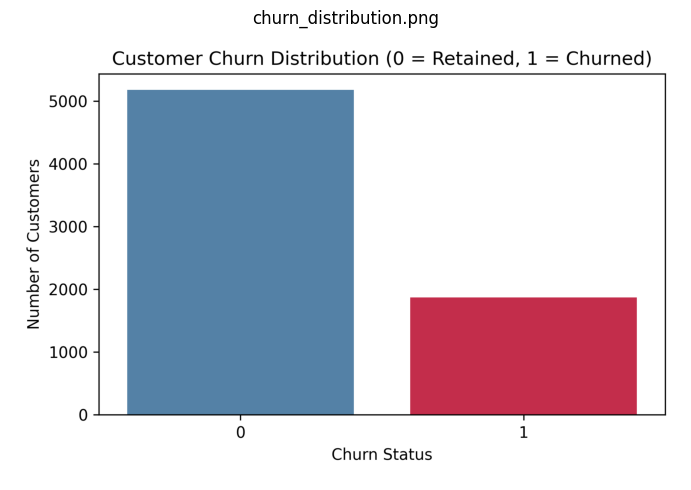

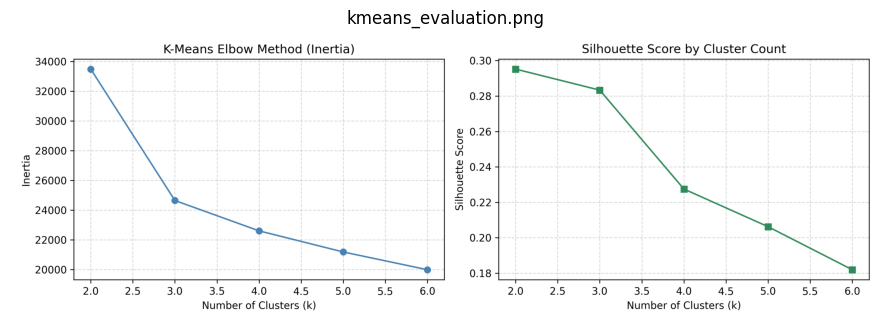

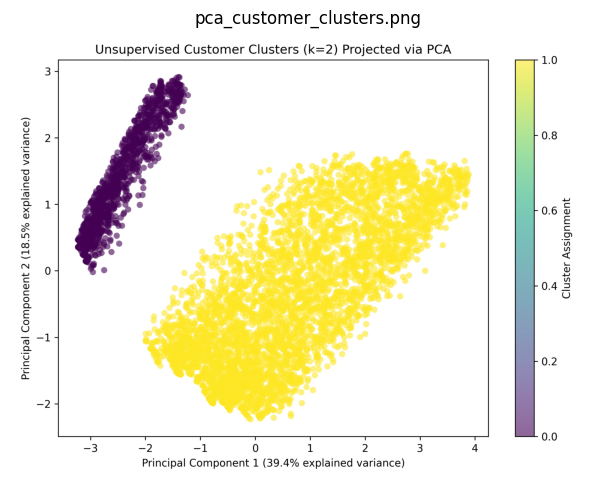

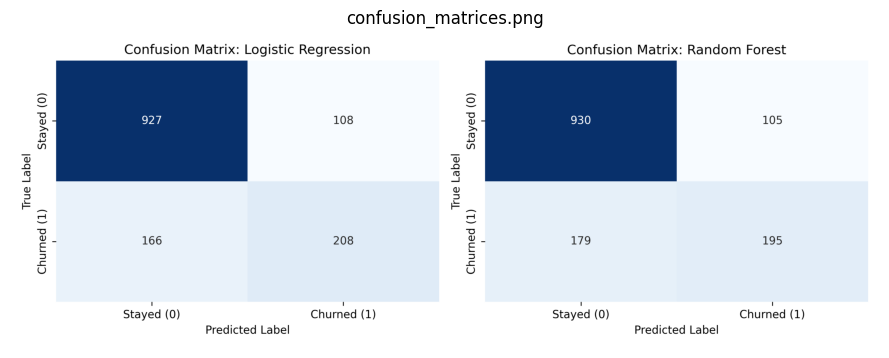

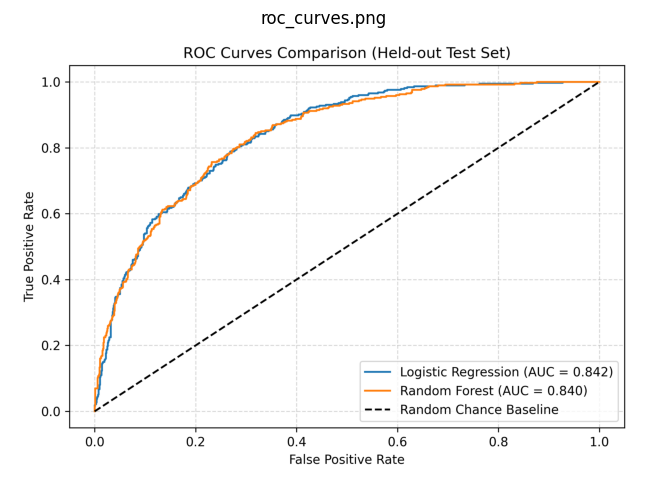

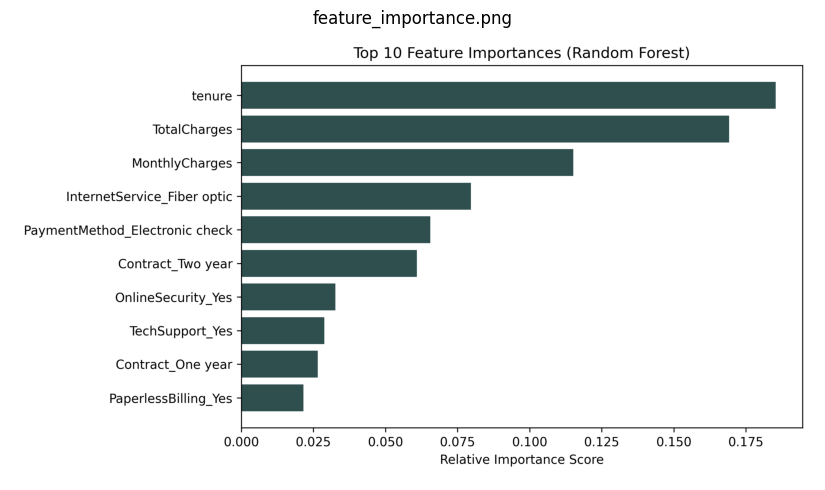

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

plot_files = [
    'churn_distribution.png',
    'kmeans_evaluation.png',
    'pca_customer_clusters.png',
    'confusion_matrices.png',
    'roc_curves.png',
    'feature_importance.png'
]

for pf in plot_files:
    path = os.path.join('outputs', pf)
    if os.path.exists(path):
        img = mpimg.imread(path)
        plt.figure(figsize=(9, 5))
        plt.imshow(img)
        plt.axis('off')
        plt.title(pf, fontsize=12)
        plt.tight_layout()
        plt.show()